# 05 · Certified recall: a promise instead of an average

**Katip lab, notebook 5.** About 5 minutes. Needs notebook 2 (and uses notebook 4's models if they exist).

### The problem

"99.9% on our benchmark" is an average over *our* documents. A lawyer about to send a file to an AI
tool needs something different: **"at most 5% of the name words in this document will stay
readable"**, and a way to know what that costs. Averages do not give that; a calibrated threshold does.

### The method: conformal risk control

1. Give every word a score: **1.0** if Katip's rules mark it as part of a name, otherwise the tagger's
   probability that it is part of a name.
2. Mask every word scoring at or above a threshold **λ**. A document's **loss** is the share of its
   name words left readable. Lowering λ masks more, so the loss can only go down.
3. On *n* calibration documents, pick the largest λ with **(n · average loss + 1) / (n + 1) ≤ α**.

Theorem (Angelopoulos et al., 2022): for a new document from the same source, the **expected** share of
name words left readable is at most **α**, for any model. No assumptions about the model being good or
calibrated. The only assumption is that calibration and new documents come from the same mix.

What the model's quality decides is the **price**: how many ordinary words must be masked (or sent to
a reviewer) to keep that promise. A better model keeps the same promise more cheaply. That turns
"which model is better" into one number lawyers understand.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import katiplab as K
import conformal as CF

real = K.load_wiki("dev") + K.load_wiki("test")       # both splits: this notebook asks a different question than 03
synthetic = K.load_synth("heldout") + K.load_synth("blind")

models = {"Tiny (published)": K.TINY}
sel = K.RESULTS / "02_selected.json"
if sel.exists(): models["Tiny-R"] = K.ROOT / json.loads(sel.read_text())["model_dirs"][0]
for name, d in [("Student (distilled)", "04_student"), ("Teacher BERTurk-R", "04_teacher")]:
    f = K.RESULTS / f"{d}.json"
    if f.exists(): models[name] = K.ROOT / json.loads(f.read_text())["dir"]
if (K.BERTURK / "onnx").exists(): models["BERTurk (synthetic only)"] = K.BERTURK
models

{'Tiny (published)': PosixPath('<repo>/hf/model'),
 'Tiny-R': PosixPath('<repo>/lab/runs/tiny_real17967_seed0')}

## 5.1 · Score every word once

For each model we store, per document, every word's (is it a name?, score). Everything after this
is arithmetic on those arrays, so it runs in seconds.

In [2]:
taggers = {n: K.Tagger(d) for n, d in models.items()}
LC_real = {n: CF.loss_cost(CF.word_scores(real, t)) for n, t in taggers.items()}
LC_syn = {n: CF.loss_cost(CF.word_scores(synthetic, t)) for n, t in taggers.items()}
LC_rules = CF.loss_cost(CF.word_scores(real, None))
print("documents with names: real", len(LC_rules[0]), " synthetic", len(next(iter(LC_syn.values()))[0]))
for n, (L, C) in LC_real.items():
    j = int(np.searchsorted(CF.GRID, 0.5))
    print(f"{n:26} at the default λ=0.5: {L[:, j].mean():.1%} of name words readable, {C[:, j].mean():.1%} of other words masked")

documents with names: real 827  synthetic 140
Tiny (published)           at the default λ=0.5: 62.5% of name words readable, 15.0% of other words masked
Tiny-R                     at the default λ=0.5: 29.9% of name words readable, 6.0% of other words masked


## 5.2 · Does the promise hold? (1,000 random splits)

Half the real documents calibrate λ̂, the other half test it. Repeat 1,000 times. If the theory is
right, the **average** test loss sits at or just under α. Single splits can land above α (the promise
is about the expectation), and the histogram shows how often.

In [3]:
ALPHAS = [0.02, 0.05, 0.10, 0.20]
rows = []
for n, (L, C) in LC_real.items():
    for a in ALPHAS:
        lam, loss, cost = CF.trials(L, C, a, reps=1000)
        rows.append({"model": n, "α (promised)": a, "λ̂ (median)": np.median(lam), "readable name words (mean)": loss.mean(),
                     "splits above α": (loss > a).mean(), "other words masked (mean)": cost.mean()})
cert = pd.DataFrame(rows)
cert.style.format({"λ̂ (median)": "{:.4f}", "readable name words (mean)": "{:.1%}", "splits above α": "{:.0%}",
                   "other words masked (mean)": "{:.1%}", "α (promised)": "{:.0%}"})

,model,α (promised),λ̂ (median),readable name words (mean),splits above α,other words masked (mean)
0,Tiny (published),2%,0.0000,0.0%,0%,99.8%
1,Tiny (published),5%,0.0000,0.0%,0%,99.8%
2,Tiny (published),10%,0.0000,0.0%,0%,99.8%
3,Tiny (published),20%,0.0000,0.0%,0%,99.8%
4,Tiny-R,2%,0.0150,1.7%,39%,15.2%
5,Tiny-R,5%,0.0550,4.7%,39%,12.9%
6,Tiny-R,10%,0.1350,9.7%,42%,10.8%
7,Tiny-R,20%,0.3200,19.7%,47%,8.0%


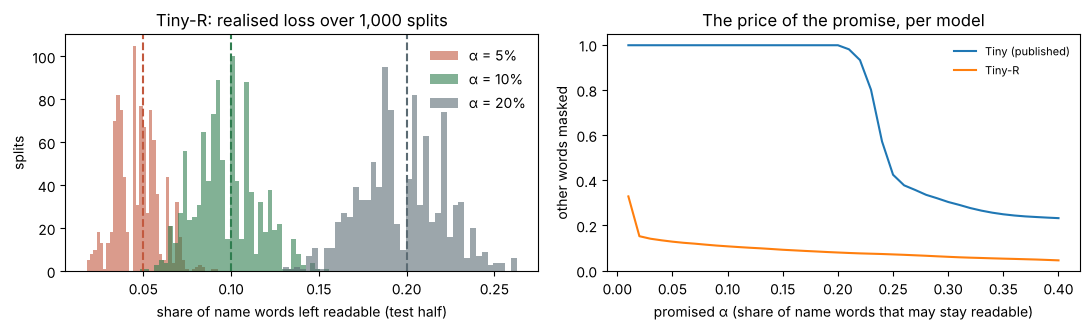

In [4]:
best = "Tiny-R" if "Tiny-R" in LC_real else next(iter(LC_real))
L, C = LC_real[best]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for a, col in zip([0.05, 0.10, 0.20], ["#c2593f", "#2f7d4f", "#5b6b73"]):
    _, loss, _ = CF.trials(L, C, a, reps=1000)
    axes[0].hist(loss, bins=40, alpha=0.6, color=col, label=f"α = {a:.0%}"); axes[0].axvline(a, color=col, ls="--")
axes[0].set_xlabel("share of name words left readable (test half)"); axes[0].set_ylabel("splits"); axes[0].legend(frameon=False)
axes[0].set_title(f"{best}: realised loss over 1,000 splits")
for n, (L2, C2) in LC_real.items():
    xs = np.linspace(0.01, 0.4, 40)
    axes[1].plot(xs, [CF.trials(L2, C2, a, reps=100)[2].mean() for a in xs], label=n)
axes[1].set_xlabel("promised α (share of name words that may stay readable)"); axes[1].set_ylabel("other words masked")
axes[1].set_title("The price of the promise, per model"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(K.RESULTS / "certified_recall.png", dpi=160); plt.show()

**How to read it.**

* *Left*: the dashed line is the promise; the bulk of each histogram sits at or below it, and the mean
  sits at it. That is the guarantee working.
* *Right*: the price curve. A model whose curve is lower keeps the same promise with less
  over-masking. A model that has never seen real text may only keep a promise by masking almost
  everything. Find where the published Tiny lands.

## 5.3 · The catch: calibrate on the documents you will protect

The guarantee needs calibration documents from the same source as the new ones. What happens if we
calibrate on Katip's **synthetic** documents and then protect **real** text?

In [5]:
rows = []
for n in LC_real:
    for a in (0.05, 0.10):
        lam, loss, cost = CF.transfer(LC_syn[n][0], *LC_real[n], a)
        rows.append({"model": n, "α": a, "λ̂ from synthetic": lam, "readable name words on real text": loss, "promise kept": loss <= a})
pd.DataFrame(rows).style.format({"α": "{:.0%}", "λ̂ from synthetic": "{:.3f}", "readable name words on real text": "{:.1%}"})

,model,α,λ̂ from synthetic,readable name words on real text,promise kept
0,Tiny (published),5%,1.000,87.2%,False
1,Tiny (published),10%,1.000,87.2%,False
2,Tiny-R,5%,1.000,87.2%,False
3,Tiny-R,10%,1.000,87.2%,False


Calibrated on synthetic documents, the promise breaks on real text, by a wide margin. This is not a
flaw in the method; it is the method telling the truth about distribution shift.

**The product consequence.** Katip already has the calibration data source: the review screen. Every
document a firm's reviewer finalises is a labelled document *from that firm*. Calibrating λ̂ on the
firm's last few hundred reviewed documents gives that firm a guarantee about *its own* documents,
and the `/report` pilot gate can show it: "λ̂ = 0.12, at most 5% of name words readable, 11% of
other words go to review".

## 5.4 · Review load instead of over-masking

In the product we do not have to mask every word above λ̂. Mask what the model is sure about (≥ 0.5)
and send the band λ̂ ≤ score < 0.5 to the reviewer. Same promise, after review.

In [6]:
rows = []
for n, (L, C) in LC_real.items():
    j5 = int(np.searchsorted(CF.GRID, 0.5))
    for a in (0.05, 0.10):
        lam = CF.calibrate(L, a); j = int(np.searchsorted(CF.GRID, lam))
        auto = C[:, j5].mean(); review = max(0.0, C[:, j].mean() - auto)
        rows.append({"model": n, "α": a, "λ̂": lam, "other words auto-masked": auto, "other words to review": review})
pd.DataFrame(rows).style.format({"α": "{:.0%}", "λ̂": "{:.4f}", "other words auto-masked": "{:.1%}", "other words to review": "{:.1%}"})

,model,α,λ̂,other words auto-masked,other words to review
0,Tiny (published),5%,0.0000,15.0%,84.7%
1,Tiny (published),10%,0.0000,15.0%,84.7%
2,Tiny-R,5%,0.0600,6.0%,6.8%
3,Tiny-R,10%,0.1400,6.0%,4.7%


In [7]:
out = {"alphas": ALPHAS, "table": cert.to_dict(orient="records"), "real_docs": int(len(LC_rules[0]))}
(K.RESULTS / "05_certified.json").write_text(json.dumps(out, indent=1, default=float))
print("saved", K.RESULTS / "05_certified.json")

saved <repo>/lab/results/05_certified.json


## Conclusion you should be able to state

> With conformal risk control, Katip can promise "at most α of name words readable" on documents
> like the calibration set, for any model. On real Turkish text, the published Tiny can only keep a
> 10% promise by masking about every word; Tiny-R keeps it while masking (or sending to review) the
> share you measured. The promise holds only when calibration documents match the protected ones, so
> calibration belongs in each firm's review loop, not in our synthetic benchmark.

Reference: A. N. Angelopoulos, S. Bates, A. Fisch, L. Lei, T. Schuster. *Conformal Risk Control.*
ICLR 2024. https://arxiv.org/abs/2208.02814